<a href="https://colab.research.google.com/github/siddala2005-ship-it/AIRBND-CLONE/blob/main/proposedModel__using_ALL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q torch torchvision timm einops scikit-learn

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import timm
import math

In [8]:
import numpy as np
import matplotlib.pyplot as plt

In [9]:
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

In [10]:
import os
import zipfile

# Create a new base directory for extracted data
base_data_path = "/content/leukemia_data"
os.makedirs(base_data_path, exist_ok=True)

train_zip_path = "/content/train_demo.zip"
train_extract_path = os.path.join(base_data_path, "training_data")
os.makedirs(train_extract_path, exist_ok=True)

test_zip_path = "/content/test_demo.zip"
test_extract_path = os.path.join(base_data_path, "testing_data")
os.makedirs(test_extract_path, exist_ok=True)

print(f"Attempting to extract {train_zip_path} to {train_extract_path} using unzip...")
!unzip -o {train_zip_path} -d {train_extract_path}

print(f"\nAttempting to extract {test_zip_path} to {test_extract_path} using unzip...")
!unzip -o {test_zip_path} -d {test_extract_path}

print("\n--- Verification of extracted contents ---")
print(f"Contents of {train_extract_path}:")
!ls -F {train_extract_path}

print(f"\nContents of {test_extract_path}:")
!ls -F {test_extract_path}

print("\nExtraction commands executed and verified. Please check output for any errors or missing files.")

# Note: This cell only runs the unzip commands. Subsequent cells will need to be re-run
# to load data once extraction is successful.


Attempting to extract /content/train_demo.zip to /content/leukemia_data/training_data using unzip...
unzip:  cannot find or open /content/train_demo.zip, /content/train_demo.zip.zip or /content/train_demo.zip.ZIP.

Attempting to extract /content/test_demo.zip to /content/leukemia_data/testing_data using unzip...
unzip:  cannot find or open /content/test_demo.zip, /content/test_demo.zip.zip or /content/test_demo.zip.ZIP.

--- Verification of extracted contents ---
Contents of /content/leukemia_data/training_data:

Contents of /content/leukemia_data/testing_data:

Extraction commands executed and verified. Please check output for any errors or missing files.


In [11]:
from torchvision.datasets import ImageFolder
from torch.utils.data import ConcatDataset, random_split, TensorDataset # Re-added TensorDataset
import torch
from torchvision import transforms

# Define transforms (moved from a previous cell)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    # Data augmentation (only training) - **ENHANCED AUGMENTATION**
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(30), # Increased rotation range
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=False), # Added RandomErasing
    # Normalize (standard for CNN/Transformer training)
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

# Base path for the newly extracted datasets
base_data_path = "/content/leukemia_data"

# Corrected paths after checking the extraction output.
# The zip files extract into a subdirectory (train_demo, test_demo) which then contains class folders.
# For training, we assume train_demo contains the 'benign'/'malignant' classes directly.
train_dirs = [
    os.path.join(base_data_path, "training_data/train_demo")
]

train_image_folders = [
    ImageFolder(root=d, transform=train_transform)
    for d in train_dirs
]

full_dataset = ConcatDataset(train_image_folders)

train_size = int(0.70 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size_split = len(full_dataset) - train_size - val_size # Renamed to avoid conflict with test_data

# Perform random split, resulting in Subset objects
train_subset, val_subset, temp_test_subset = random_split(
    full_dataset,
    [train_size, val_size, test_size_split],
    generator=torch.Generator().manual_seed(42)
)

# Convert Subsets to TensorDatasets to avoid potential indexing issues
# This step might be memory intensive for very large datasets
def convert_subset_to_tensor_dataset(subset):
    images = []
    labels = []
    # Iterate through the subset to get all image-label pairs
    for i in range(len(subset)):
        img, label = subset[i]
        images.append(img)
        labels.append(label)
    # Stack images and labels into tensors for TensorDataset
    return TensorDataset(torch.stack(images), torch.tensor(labels))

print("Converting train_subset to TensorDataset...")
train_data = convert_subset_to_tensor_dataset(train_subset)
print("Converting val_subset to TensorDataset...")
val_data = convert_subset_to_tensor_dataset(val_subset)

# The original test_data remains an ImageFolder from a different path.
# This part needs attention if you intend to calculate accuracy on 'all'/'hem' classes.
test_data = ImageFolder(
    root=os.path.join(base_data_path, "testing_data/test_demo"), # Corrected path for test_data
    transform=test_transform
)

classes = train_image_folders[0].classes
num_classes = len(classes)

print("Classes:", classes)
print("Train images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))
print("Total images:", len(train_data) + len(test_data))


FileNotFoundError: [Errno 2] No such file or directory: '/content/leukemia_data/training_data/train_demo'

In [ ]:
def get_labels(dataset):
    return [dataset[i][1] for i in range(len(dataset))]

imbalance fix

In [ ]:
import numpy as np
from torch.utils.data import WeightedRandomSampler

# train_data is now a TensorDataset. Its labels are directly accessible from its tensors.
# Ensure labels are extracted as a simple list of integers for np.bincount.
train_labels = train_data.tensors[1].cpu().numpy().tolist()

class_counts = np.bincount(train_labels)
class_weights = 1.0 / class_counts

sample_weights = [class_weights[label] for label in train_labels]

sampler = WeightedRandomSampler(
    sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

added pin_memory to train and test loader

In [ ]:
from torch.utils.data import DataLoader # Added import for DataLoader
import os

train_loader = DataLoader(
    train_data,
    batch_size=32,
    sampler=sampler,
    pin_memory=True,
    num_workers=os.cpu_count() - 1 if os.cpu_count() > 1 else 0 # Optimized num_workers
)

val_loader = DataLoader(
    val_data,
    batch_size=32,
    shuffle=False,
    pin_memory=True,
    num_workers=os.cpu_count() - 1 if os.cpu_count() > 1 else 0 # Optimized num_workers
)

test_loader = DataLoader(
    test_data,
    batch_size=32,
    shuffle=False,
    pin_memory=True,
    num_workers=os.cpu_count() - 1 if os.cpu_count() > 1 else 0 # Optimized num_workers
)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

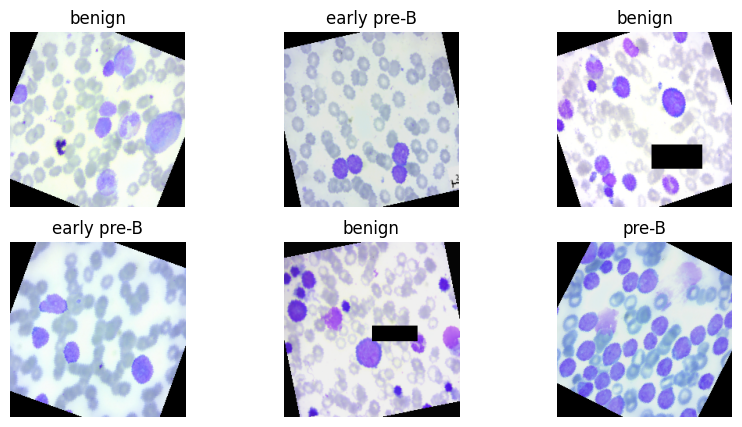

In [ ]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10,5))

for i in range(6):
    img = images[i].permute(1,2,0).numpy()
    img = (img * 0.5) + 0.5

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(classes[labels[i]])
    plt.axis("off")

plt.show()

In [ ]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.depthwise = nn.Conv2d(in_ch, in_ch, kernel_size=3, padding=1, groups=in_ch)
        self.pointwise = nn.Conv2d(in_ch, out_ch, kernel_size=1)

        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.GELU()

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        return self.act(self.bn(x))

added scconv

In [ ]:
class SCConv(nn.Module):
    def __init__(self, dim):
        super().__init__()

        self.spatial = nn.Conv2d(dim, dim, 3, padding=1, groups=dim)
        self.channel = nn.Conv2d(dim, dim, 1)

        self.bn = nn.BatchNorm2d(dim)
        self.act = nn.GELU()

    def forward(self, x):
        x = self.spatial(x)
        x = self.channel(x)
        x = self.bn(x)
        return self.act(x)

changed dim to 32 from 128
2.added sc encoder
3.DIM CHANGED TO 64

In [ ]:
class PatchEmbedding(nn.Module):
    def __init__(self, in_ch=3, dim=64):
        super().__init__()

        self.proj = nn.Sequential(
            DepthwiseSeparableConv(in_ch, dim),
            SCConv(dim),
            nn.MaxPool2d(4)   # downsampling
        )

    def forward(self, x):
        return self.proj(x)

commented rbf function

In [ ]:
class FastKANLayer(nn.Module):
    """
    Gaussian RBF-based KAN layer
    φ(x) = exp(-(x - c)^2 / h^2)
    """

    def __init__(self, in_features, out_features, num_centers=4):
        super().__init__()

        self.in_features = in_features
        self.out_features = out_features
        self.num_centers = num_centers

        # learnable centers and bandwidths
        self.centers = nn.Parameter(torch.randn(out_features, num_centers, in_features))
        self.bandwidth = nn.Parameter(torch.ones(out_features, num_centers))

        self.linear = nn.Linear(in_features, out_features)

   ## def rbf(self, x, c, h):
     ##   return torch.exp(-((x - c) ** 2).mean(dim=-1) / (h ** 2 + 1e-6))

    def forward(self, x):
        # x: [B, F]
        B = x.size(0)

        x_expanded = x.unsqueeze(1).unsqueeze(2)  # [B,1,1,F]

        c = self.centers.unsqueeze(0)  # [1,O,C,F]
        h = self.bandwidth.unsqueeze(0).unsqueeze(-1)

        diff = (x_expanded - c).pow(2).mean(dim=-1)
        rbf_out = torch.exp(-diff / (h.squeeze(-1) ** 2 + 1e-6))

        rbf_out = rbf_out.mean(dim=2)  # aggregate centers

        return self.linear(x) + rbf_out

In [ ]:
class FastKAN(nn.Module):
    def __init__(self, dim):
        super().__init__()

        self.layer1 = FastKANLayer(dim, dim * 2)
        self.layer2 = FastKANLayer(dim * 2, dim)

        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        x = self.layer1(x)
        x = F.gelu(x)
        x = self.layer2(x)
        return self.norm(x)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class LinearAttention(nn.Module):
    """
    Performer-style linear attention (O(N) complexity)
    """

    def __init__(self, dim):
        super().__init__()

        self.to_q = nn.Linear(dim, dim)
        self.to_k = nn.Linear(dim, dim)
        self.to_v = nn.Linear(dim, dim)

        self.scale = dim ** -0.5

    def feature_map(self, x):
        # Positive feature map (softmax approximation)
        return F.elu(x) + 1

    def forward(self, x):
        """
        x: [B, N, D]
        """
        Q = self.feature_map(self.to_q(x))
        K = self.feature_map(self.to_k(x))
        V = self.to_v(x)

        # KV aggregation
        KV = torch.einsum("bnd,bne->bde", K, V)

        # normalization term
        Z = 1 / (torch.einsum("bnd,bd->bn", Q, K.sum(dim=1)) + 1e-6)

        # output
        out = torch.einsum("bnd,bde,bn->bne", Q, KV, Z)

        return out

In [ ]:
class FastKAN_SCKansformer(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        DIM=64
        # smaller dimensions
        self.patch = PatchEmbedding(3,DIM )

        self.fastkan = FastKAN(DIM)

        # REMOVE attention for CPU speed
        self.attn = LinearAttention(DIM)

        self.pool = nn.AdaptiveAvgPool2d((1,1))

        self.classifier = nn.Sequential(
            nn.Linear(DIM, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):

       x = self.patch(x)

       B, C, H, W = x.shape

       x = x.flatten(2).transpose(1, 2)   # [B, HW, C]

       x = self.attn(x)

       x = x.mean(dim=1)
       x = self.fastkan(x)

       return self.classifier(x)

adding learning rate

teacher model added

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
model = FastKAN_SCKansformer(num_classes=num_classes).to(device)

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

In [ ]:
import torch.optim.lr_scheduler

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs, # Max number of iterations, typically set to total epochs
    eta_min=1e-6 # Minimum learning rate
)

In [ ]:
teacher_model = timm.create_model(
    "resnet18",
    pretrained=True,
    num_classes=num_classes
).to(device)

teacher_model.eval()
for param in teacher_model.parameters():
    param.requires_grad = False

In [ ]:
teacher_model = teacher_model.to(device)

distillation loss

In [ ]:
def distillation_loss(student_out, teacher_out, labels, T=2.0, alpha=0.5):

    soft_loss = F.kl_div(
        F.log_softmax(student_out / T, dim=1),
        F.softmax(teacher_out / T, dim=1),
        reduction='batchmean'
    ) * (T * T)

    hard_loss = F.cross_entropy(student_out, labels)

    return alpha * soft_loss + (1 - alpha) * hard_loss

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(loader), correct / total

In [ ]:
pip install -q torchinfo

In [ ]:
import torchinfo
torchinfo.summary(model, input_size=(1, 3, 224, 224), device=device)

Layer (type:depth-idx)                        Output Shape              Param #
FastKAN_SCKansformer                          [1, 4]                    --
├─PatchEmbedding: 1-1                         [1, 64, 56, 56]           --
│    └─Sequential: 2-1                        [1, 64, 56, 56]           --
│    │    └─DepthwiseSeparableConv: 3-1       [1, 64, 224, 224]         414
│    │    └─SCConv: 3-2                       [1, 64, 224, 224]         4,928
│    │    └─MaxPool2d: 3-3                    [1, 64, 56, 56]           --
├─LinearAttention: 1-2                        [1, 3136, 64]             --
│    └─Linear: 2-2                            [1, 3136, 64]             4,160
│    └─Linear: 2-3                            [1, 3136, 64]             4,160
│    └─Linear: 2-4                            [1, 3136, 64]             4,160
├─FastKAN: 1-3                                [1, 64]                   --
│    └─FastKANLayer: 2-5                      [1, 128]                  33,280
│  

In [ ]:
print(test_data.class_to_idx)

{'benign': 0, 'early pre-B': 1, 'pre-B': 2, 'pro-B': 3}


loss changed

In [ ]:
best_acc = 0
epochs = 100

In [ ]:


for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    # ================= TRAINING =================
    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        # Teacher predictions
        with torch.no_grad():
            teacher_outputs = teacher_model(images)

        # Distillation loss
        loss = distillation_loss(
            outputs,
            teacher_outputs,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()

        total_loss += loss.item()

        preds = outputs.argmax(1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

    train_acc = correct / total
    train_loss = total_loss / len(train_loader)

    # ================= VALIDATION =================
    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            preds = outputs.argmax(1)

            val_correct += (preds == labels).sum().item()

            val_total += labels.size(0)

    val_acc = val_correct / val_total

    # ================= PRINT RESULTS =================
    print(f"\nEpoch {epoch+1}")

    print("Loss:", train_loss)

    print("Train Acc:", train_acc)


    print("Validation Acc:", val_acc)


    # ================= LR SCHEDULER =================
    scheduler.step()

    # ================= SAVE BEST MODEL =================
    if val_acc > best_acc:

        best_acc = val_acc

        torch.save(
            model.state_dict(),
            "best_model.pth"
        )


Epoch 1
Loss: 0.42296007981425837
Train Acc: 0.9375527426160337
Validation Acc: 0.968503937007874

Epoch 2
Loss: 0.4202750497742703
Train Acc: 0.9662447257383966
Validation Acc: 0.9763779527559056

Epoch 3
Loss: 0.4196596302484211
Train Acc: 0.9544303797468354
Validation Acc: 0.9803149606299213

Epoch 4
Loss: 0.42740287435682195
Train Acc: 0.9654008438818565
Validation Acc: 0.9803149606299213

Epoch 5
Loss: 0.43871342665270757
Train Acc: 0.9409282700421941
Validation Acc: 0.984251968503937

Epoch 6
Loss: 0.43137127631588984
Train Acc: 0.9552742616033755
Validation Acc: 0.9724409448818898

Epoch 7
Loss: 0.4165882397639124
Train Acc: 0.960337552742616
Validation Acc: 0.9606299212598425

Epoch 8
Loss: 0.4248650842591336
Train Acc: 0.9476793248945148
Validation Acc: 0.984251968503937

Epoch 9
Loss: 0.42750371443597895
Train Acc: 0.9527426160337553
Validation Acc: 0.9763779527559056

Epoch 10
Loss: 0.4214663913375453
Train Acc: 0.9561181434599156
Validation Acc: 0.9763779527559056

Epoch 1

KeyboardInterrupt: 

In [ ]:
print("Validation Acc:", val_acc)
print("Train Acc:", train_acc)
print("Best Validation Acc:", best_acc)

Validation Acc: 0.968503937007874
Train Acc: 0.9561181434599156
Best Validation Acc: 0.9881889763779528


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

train_acc_list = []
val_acc_list = []
loss_list = []

best_acc = 0

epochs = 25

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        with torch.no_grad():
            teacher_outputs = teacher_model(images)

        loss = distillation_loss(outputs, teacher_outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_acc = correct / total
    train_loss = total_loss / len(train_loader)

    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            preds = outputs.argmax(1)

            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total

    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
    loss_list.append(train_loss)

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "best_model.pth")

    print(f"Epoch {epoch+1} | Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

print("\nBEST VAL ACC:", best_acc)

# ================= PLOTS =================
plt.figure(figsize=(10,5))
plt.plot(train_acc_list, label="Train Accuracy")
plt.plot(val_acc_list, label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(loss_list, label="Loss")
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# ================= TEST EVALUATION =================
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

test_correct = 0
test_total = 0

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        test_correct += (preds == labels).sum().item()
        test_total += labels.size(0)

print("\nFINAL TEST ACCURACY:", test_correct / test_total)

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

NameError: name 'model' is not defined

In [ ]:
images, labels = next(iter(train_loader))

print(labels)
for l in labels:
    print(l.item(), "->", classes[l.item()])

tensor([2, 3, 1, 2, 1, 0, 2, 0, 2, 1, 1, 3, 3, 0, 0, 2, 2, 2, 0, 3, 1, 3, 3, 3,
        3, 3, 2, 0, 2, 1, 1, 2])
2 -> pre-B
3 -> pro-B
1 -> early pre-B
2 -> pre-B
1 -> early pre-B
0 -> benign
2 -> pre-B
0 -> benign
2 -> pre-B
1 -> early pre-B
1 -> early pre-B
3 -> pro-B
3 -> pro-B
0 -> benign
0 -> benign
2 -> pre-B
2 -> pre-B
2 -> pre-B
0 -> benign
3 -> pro-B
1 -> early pre-B
3 -> pro-B
3 -> pro-B
3 -> pro-B
3 -> pro-B
3 -> pro-B
2 -> pre-B
0 -> benign
2 -> pre-B
1 -> early pre-B
1 -> early pre-B
2 -> pre-B


In [ ]:
print(test_data.classes)
print(len(test_data))

['benign', 'early pre-B', 'pre-B', 'pro-B']
738


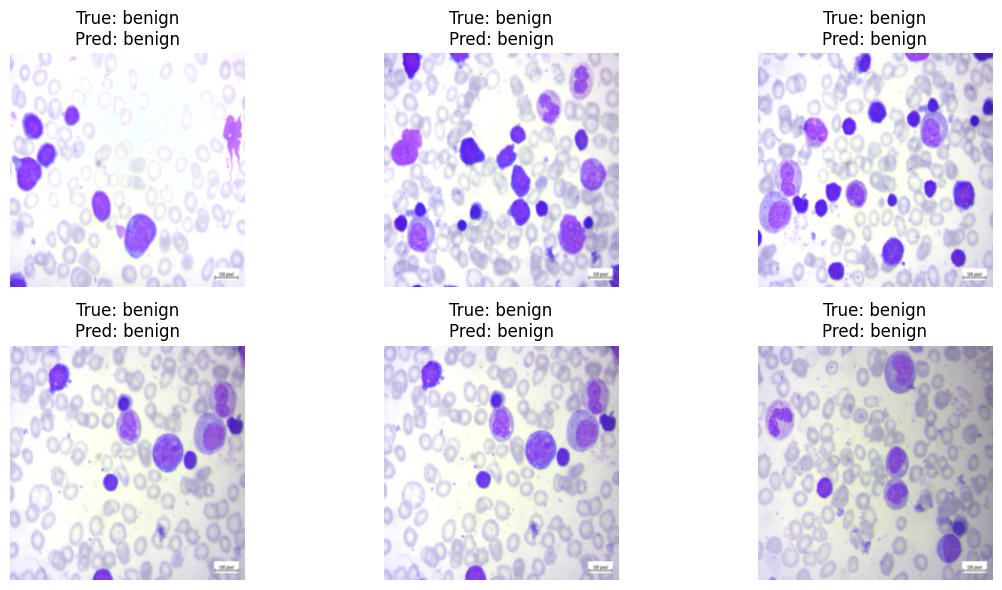

In [ ]:
import matplotlib.pyplot as plt
import torch

model.load_state_dict(torch.load("best_model.pth"))
model.to(device)
model.eval()

class_names = test_data.classes  # or train_data.classes if same mapping

images, labels = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)
    preds = outputs.argmax(1)

plt.figure(figsize=(12, 6))

for i in range(6):
    img = images[i].cpu().permute(1, 2, 0).numpy()
    img = (img * 0.5) + 0.5  # undo normalization

    plt.subplot(2, 3, i+1)
    plt.imshow(img)

    true_label = class_names[labels[i]]
    pred_label = class_names[preds[i].cpu().item()]

    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Final Test Evaluation


FINAL TEST ACCURACY: 0.9851


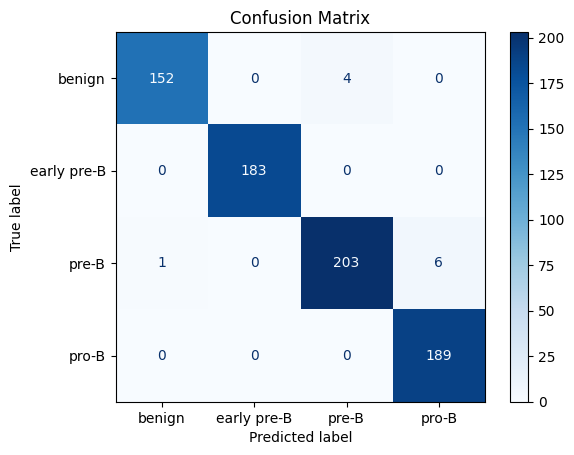

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load the best model weights
model.load_state_dict(torch.load("best_model.pth"))
model.eval() # Set model to evaluation mode

test_correct = 0
test_total = 0

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        test_correct += (preds == labels).sum().item()
        test_total += labels.size(0)

final_test_accuracy = test_correct / test_total
print(f"\nFINAL TEST ACCURACY: {final_test_accuracy:.4f}")

# Display Confusion Matrix
cm = confusion_matrix(all_labels, all_preds, labels=range(len(classes)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

### Final Classification Results

In [ ]:
import pandas as pd

print(f"Overall Final Test Accuracy: {final_test_accuracy:.4f}")

# Display Confusion Matrix as a DataFrame
cm_df = pd.DataFrame(
    cm,
    index=[f'True_{cls}' for cls in classes],
    columns=[f'Pred_{cls}' for cls in classes]
)

print("\nConfusion Matrix (Table Format):")
display(cm_df)

Overall Final Test Accuracy: 0.9851

Confusion Matrix (Table Format):


,Pred_benign,Pred_early pre-B,Pred_pre-B,Pred_pro-B
True_benign,152,0,4,0
True_early pre-B,0,183,0,0
True_pre-B,1,0,203,6
True_pro-B,0,0,0,189


In [12]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay
from itertools import cycle

# Get predicted probabilities for the test set
all_probs = []
all_labels_one_hot = []

model.eval() # Ensure model is in evaluation mode
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        probabilities = F.softmax(outputs, dim=1) # Get probabilities
        all_probs.extend(probabilities.cpu().numpy())

        # Convert labels to one-hot encoding for ROC curve calculation
        labels_one_hot = torch.nn.functional.one_hot(labels, num_classes=len(classes)).cpu().numpy()
        all_labels_one_hot.extend(labels_one_hot)

all_probs = np.array(all_probs)
all_labels_one_hot = np.array(all_labels_one_hot)

NameError: name 'FastKAN_SCKansformer' is not defined

In [ ]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay
from itertools import cycle
import torch
import torch.nn.functional as F
import numpy as np

# Ensure 'model', 'device', 'num_classes', 'classes', 'test_loader' are already defined
# from previous cells, and FastKAN_SCKansformer class is available.

# Initialize the model if it's not already defined
# This assumes FastKAN_SCKansformer, num_classes, and device are defined in prior cells
# We add this initialization for robustness in case the model object is lost
if 'model' not in locals():
    model = FastKAN_SCKansformer(num_classes=num_classes).to(device)

# Load the best model weights into the existing model
model.load_state_dict(torch.load("best_model.pth"))
model.to(device) # Ensure model is on the correct device

# Get predicted probabilities for the test set
all_probs = []
all_labels_one_hot = []

model.eval() # Ensure model is in evaluation mode
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        probabilities = F.softmax(outputs, dim=1) # Get probabilities
        all_probs.extend(probabilities.cpu().numpy())

        # Convert labels to one-hot encoding for ROC curve calculation
        labels_one_hot = torch.nn.functional.one_hot(labels, num_classes=len(classes)).cpu().numpy()
        all_labels_one_hot.extend(labels_one_hot)

all_probs = np.array(all_probs)
all_labels_one_hot = np.array(all_labels_one_hot)

In [2]:
# Compute ROC curve and AUC for each class
n_classes = len(classes)

fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(all_labels_one_hot[:, i], all_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and micro-average AUC
fpr["micro"], tpr["micro"], _ = roc_curve(all_labels_one_hot.ravel(), all_probs.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

NameError: name 'classes' is not defined

In [5]:
# Plot all ROC curves
plt.figure(figsize=(10, 8))

plt.plot(
    fpr["micro"],
    tpr["micro"],
    label=f"micro-average ROC curve (area = {roc_auc['micro']:.2f})",
    color="deeppink",
    linestyle=":",
    linewidth=4,
)

colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple'])
for i, color in zip(range(n_classes), colors):
    plt.plot(
        fpr[i],
        tpr[i],
        color=color,
        lw=2,
        label=f"ROC curve of class {classes[i]} (area = {roc_auc[i]:.2f})",
    )

plt.plot([0, 1], [0, 1], "k--", lw=2, label="Chance level (AUC = 0.5)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

NameError: name 'fpr' is not defined

<Figure size 1000x800 with 0 Axes>

In [ ]:
# Plot all ROC curves
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.plot(
    fpr["micro"],
    tpr["micro"],
    label=f"micro-average ROC curve (area = {roc_auc['micro']:.2f})",
    color="deeppink",
    linestyle=":",
    linewidth=4,
)

colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple'])
for i, color in zip(range(n_classes), colors):
    plt.plot(
        fpr[i],
        tpr[i],
        color=color,
        lw=2,
        label=f"ROC curve of class {classes[i]} (area = {roc_auc[i]:.2f})",
    )

plt.plot([0, 1], [0, 1], "k--", lw=2, label="Chance level (AUC = 0.5)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()